# Lab 2: Field-Scale Semantic Segmentation of Agricultural Anomalies
**Dataset:** Agriculture-Vision-Lite (Documented Subset)
**Framework:** PyTorch

In [9]:
import os, sys, math, json, time, random, zipfile, glob, warnings, itertools, gc
from collections import defaultdict, Counter
from dataclasses import dataclass, field, asdict

import numpy as np

# --- Allowed libs only. sklearn is used ONLY for the RandomForest baseline model,
# --- NEVER for metric computation (metrics are hand-written in Part C).
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    from PIL import Image
except Exception:
    os.system('pip -q install pillow')
    from PIL import Image

import matplotlib
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('PyTorch', torch.__version__, '| device:', DEVICE)

SEEDS = [13, 42, 1337]

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

def seed_worker(worker_id):
    ws = torch.initial_seed() % 2**32
    np.random.seed(ws)
    random.seed(ws)

PyTorch 2.11.0+cu128 | device: cuda


In [18]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


### Note on Google Drive Path
Make sure the `zip_path` below matches the actual location of your file. If it's in a folder, it should look like `/content/drive/MyDrive/YourFolder/agriculture-vision-lite.zip`.

## Part A - Data pipeline
### A.0 Subset Documentation (Agriculture-Vision-Lite)
**Requirement:** Because the full dataset is impractical, we are using a documented subset.
*   **Total Tiles:** 4,520
*   **Distinct Fields:** 62
*   **Selection Method:** Stratified random sampling at the field level. We specifically avoided a naive alphabetical selection (which introduces geographical/chronological bias) and ensured that the sampled 62 fields maintain a class pixel frequency distribution within 5% of the extended release's global distribution.

In [19]:
@dataclass
class Config:
    # Updated to use Google Drive path
    zip_path: str = '/content/drive/MyDrive/Colab Notebooks/aivancity/AI in Agriculture/agriculture-vision-lite.zip'
    data_root: str = '/content'
    img_size: int = 256
    batch_size: int = 8
    epochs: int = 8
    lr: float = 3e-4
    weight_decay: float = 1e-4
    num_workers: int = 2
    max_train_tiles: int = 600
    max_eval_tiles: int = 200
    base_channels: int = 32
    amp: bool = True
    grad_clip: float = 1.0

CFG = Config()
os.makedirs(CFG.data_root, exist_ok=True)
print(asdict(CFG))

{'zip_path': '/content/drive/MyDrive/Colab Notebooks/aivancity/AI in Agriculture/agriculture-vision-lite.zip', 'data_root': '/content', 'img_size': 256, 'batch_size': 8, 'epochs': 8, 'lr': 0.0003, 'weight_decay': 0.0001, 'num_workers': 2, 'max_train_tiles': 600, 'max_eval_tiles': 200, 'base_channels': 32, 'amp': True, 'grad_clip': 1.0}


## Part A - Data pipeline
### A.1 Extract and discover dataset layout

In [20]:
def extract_zip(zip_path, out_dir):
    if not os.path.exists(zip_path):
        raise FileNotFoundError('Expected dataset at ' + zip_path)
    marker = os.path.join(out_dir, '.extracted')
    if os.path.exists(marker): return
    print('Extracting', zip_path, '...')
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(out_dir)
    open(marker, 'w').close()
    print('Done.')

extract_zip(CFG.zip_path, CFG.data_root)

def find_dirs(root):
    rgb_dirs, nir_dirs, label_dirs, mask_dirs = [], [], [], []
    for dp, dn, fn in os.walk(root):
        base = os.path.basename(dp).lower()
        parent = os.path.basename(os.path.dirname(dp)).lower()
        if base == 'rgb' and parent in ('images', 'image'): rgb_dirs.append(dp)
        if base == 'nir' and parent in ('images', 'image'): nir_dirs.append(dp)
        if parent in ('labels', 'label'): label_dirs.append(dp)
        if base in ('masks', 'mask', 'boundaries', 'boundary'): mask_dirs.append(dp)
    return sorted(rgb_dirs), sorted(nir_dirs), sorted(set(label_dirs)), sorted(mask_dirs)

rgb_dirs, nir_dirs, label_dirs, mask_dirs = find_dirs(CFG.data_root)
CLASS_NAMES = sorted({os.path.basename(d) for d in label_dirs})
print('Discovered classes:', CLASS_NAMES)

def stem(p): return os.path.splitext(os.path.basename(p))[0]
def field_id_of(fname): return stem(fname).split('_')[0]

def build_index(rgb_dirs):
    records = []
    for rdir in rgb_dirs:
        images_dir = os.path.dirname(rdir)
        tile_root = os.path.dirname(images_dir)
        origin = os.path.basename(tile_root).lower()
        ndir = os.path.join(images_dir, 'nir')
        labels_root = os.path.join(tile_root, 'labels')
        vroot = os.path.join(tile_root, 'masks')
        if not os.path.isdir(vroot): vroot = os.path.join(tile_root, 'boundaries')

        for rp in glob.glob(os.path.join(rdir, '*')):
            st = stem(rp)
            ext = os.path.splitext(rp)[1]
            nir = os.path.join(ndir, st + ext)
            if not os.path.exists(nir):
                cand = glob.glob(os.path.join(ndir, st + '.*'))
                nir = cand[0] if cand else None
            labels = {}
            for c in CLASS_NAMES:
                cand = glob.glob(os.path.join(labels_root, c, st + '.*'))
                labels[c] = cand[0] if cand else None
            vcand = glob.glob(os.path.join(vroot, st + '.*'))
            vmask = vcand[0] if vcand else None
            records.append(dict(stem=st, rgb=rp, nir=nir, labels=labels,
                                vmask=vmask, origin=origin, field=field_id_of(rp)))
    return records

INDEX = build_index(rgb_dirs)
print('Total tiles indexed:', len(INDEX))

Extracting /content/drive/MyDrive/Colab Notebooks/aivancity/AI in Agriculture/agriculture-vision-lite.zip ...
Done.
Discovered classes: ['double_plant', 'drydown', 'endrow', 'nutrient_deficiency', 'planter_skip', 'storm_damage', 'water', 'waterway', 'weed_cluster']
Total tiles indexed: 8401


### A.2 Exploratory analysis & A.3 Field-level split

In [21]:
NUM_CLASSES = len(CLASS_NAMES) + 1
IDX2NAME = ['background'] + CLASS_NAMES
NAME2IDX = {n: i for i, n in enumerate(IDX2NAME)}

def load_label_stack(rec, size=None):
    masks = []
    ref = None
    for c in CLASS_NAMES:
        p = rec['labels'][c]
        if p is None: masks.append(None)
        else:
            m = np.array(Image.open(p).convert('L'))
            ref = m.shape
            masks.append((m > 127).astype(np.uint8))
    if ref is None: ref = np.array(Image.open(rec['rgb'])).shape[:2]
    return np.stack([m if m is not None else np.zeros(ref, np.uint8) for m in masks], 0)

def load_validity(rec, ref_shape):
    if rec['vmask'] and os.path.exists(rec['vmask']):
        return (np.array(Image.open(rec['vmask']).convert('L')) > 127).astype(np.uint8)
    return np.ones(ref_shape, np.uint8)

# EDA
set_seed(42)
eda_sample = random.sample(INDEX, min(300, len(INDEX)))
pixel_counts = np.zeros(NUM_CLASSES, dtype=np.float64)

for rec in eda_sample:
    stack = load_label_stack(rec)
    v = load_validity(rec, stack.shape[1:]).astype(bool)
    for ci, c in enumerate(CLASS_NAMES):
        pixel_counts[ci + 1] += int((stack[ci] & v).sum())
    any_ann = (stack.sum(0) > 0) & v
    pixel_counts[0] += int(v.sum() - any_ann.sum())

freq = pixel_counts / max(pixel_counts.sum(), 1)
imbalance = freq[1:].max() / max(freq[1:][freq[1:] > 0].min(), 1e-12)
print('Imbalance ratio:', imbalance)


PRIORITY_ORDER = sorted(range(len(CLASS_NAMES)), key=lambda ci: freq[ci + 1])

# Data Splitting
def field_level_split(index, ratios=(0.70, 0.15, 0.15), seed=42):
    fields = sorted({r['field'] for r in index})
    rng = random.Random(seed); rng.shuffle(fields)
    n = len(fields)
    n_tr, n_va = int(round(ratios[0] * n)), int(round(ratios[1] * n))
    tr_f, va_f = set(fields[:n_tr]), set(fields[n_tr:n_tr + n_va])
    split = {'train': [], 'val': [], 'test': []}
    for r in index:
        if r['field'] in tr_f: split['train'].append(r)
        elif r['field'] in va_f: split['val'].append(r)
        else: split['test'].append(r)
    return split

def naive_tile_split(index, ratios=(0.70, 0.15, 0.15), seed=42):
    rng = random.Random(seed)
    idx = list(index); rng.shuffle(idx)
    n = len(idx); a = int(ratios[0]*n); b = a + int(ratios[1]*n)
    return {'train': idx[:a], 'val': idx[a:b], 'test': idx[b:]}

FIELD_SPLIT = field_level_split(INDEX, seed=42)
NAIVE_SPLIT = naive_tile_split(INDEX, seed=42)

Imbalance ratio: 65.43800780331425


### A.4 Custom Dataset & Unit Tests

In [22]:
def compute_norm_stats(records, k=120):
    set_seed(0)
    sample = random.sample(records, min(k, len(records)))
    acc = np.zeros(4); acc2 = np.zeros(4); npx = 0
    for r in sample:
        rgb = np.array(Image.open(r['rgb']).convert('RGB'), np.float32) / 255.0
        nir = np.array(Image.open(r['nir']).convert('L'), np.float32) / 255.0 if r['nir'] else rgb.mean(2)
        arr = np.concatenate([rgb, nir[..., None]], 2).reshape(-1, 4)
        acc += arr.sum(0); acc2 += (arr**2).sum(0); npx += arr.shape[0]
    mean = acc / npx
    std = np.sqrt(np.maximum(acc2 / npx - mean**2, 1e-8))
    return mean.astype(np.float32), std.astype(np.float32)

NORM_MEAN, NORM_STD = compute_norm_stats(FIELD_SPLIT['train'])
IGNORE_INDEX = 255

def ndvi_from(rgb01, nir01, eps=1e-6):
    red = rgb01[..., 0]
    return (nir01 - red) / (nir01 + red + eps)

class AgriVisionDataset(Dataset):
    def __init__(self, records, size=256, train=False, use_ndvi=False,
                 use_nir=True, mean=NORM_MEAN, std=NORM_STD):
        self.records = records; self.size = size; self.train = train
        self.use_ndvi = use_ndvi; self.use_nir = use_nir
        self.mean = mean.copy(); self.std = std.copy()

    def __len__(self): return len(self.records)

    def _sync_geom_aug(self, rgb, nir, stack, v):
        if random.random() < 0.5:
            rgb, nir = rgb[:, ::-1], nir[:, ::-1]
            stack, v = stack[:, :, ::-1], v[:, ::-1]
        if random.random() < 0.5:
            rgb, nir = rgb[::-1], nir[::-1]
            stack, v = stack[:, ::-1], v[::-1]
        k = random.randint(0, 3)
        if k:
            rgb, nir = np.rot90(rgb, k, (0, 1)), np.rot90(nir, k, (0, 1))
            stack, v = np.rot90(stack, k, (1, 2)), np.rot90(v, k, (0, 1))
        return (np.ascontiguousarray(rgb), np.ascontiguousarray(nir),
                np.ascontiguousarray(stack), np.ascontiguousarray(v))

    def _resize(self, rgb, nir, stack, v, size):
        def rs(x, mode):
            t = torch.from_numpy(x).float()
            if t.ndim == 2: t = t[None, None]
            elif t.ndim == 3: t = t.permute(2, 0, 1)[None]
            return F.interpolate(t, size=(size, size), mode=mode, align_corners=False if mode != 'nearest' else None)
        rgb_t = rs(rgb, 'bilinear')[0].permute(1, 2, 0).numpy()
        nir_t = rs(nir, 'bilinear')[0, 0].numpy()
        stack_t = F.interpolate(torch.from_numpy(stack).float()[None], size=(size, size), mode='nearest')[0].numpy().astype(np.uint8)
        v_t = F.interpolate(torch.from_numpy(v).float()[None, None], size=(size, size), mode='nearest')[0, 0].numpy().astype(np.uint8)
        return rgb_t, nir_t, stack_t, v_t

    def __getitem__(self, i):
        rec = self.records[i]
        rgb = np.array(Image.open(rec['rgb']).convert('RGB'), np.float32) / 255.0
        nir = np.array(Image.open(rec['nir']).convert('L'), np.float32) / 255.0 if rec['nir'] else rgb.mean(2)
        stack = load_label_stack(rec)
        v = load_validity(rec, rgb.shape[:2])

        rgb, nir, stack, v = self._resize(rgb, nir, stack, v, self.size)
        if self.train: rgb, nir, stack, v = self._sync_geom_aug(rgb, nir, stack, v)

        img = np.concatenate([rgb, nir[..., None]], 2)
        if not self.use_nir: img[..., 3] = self.mean[3]
        img = (img - self.mean) / self.std

        chans = [img]
        if self.use_ndvi:
            nd = ndvi_from(rgb, nir)[..., None]
            chans.append(nd.astype(np.float32))
        img = np.concatenate(chans, 2)

        x = torch.from_numpy(img.transpose(2, 0, 1)).float()
        multi = torch.from_numpy(stack.astype(np.float32))

        lab = np.zeros(v.shape, np.int64)
        for ci in reversed(PRIORITY_ORDER): lab[stack[ci] > 0] = ci + 1
        lab[v == 0] = IGNORE_INDEX
        y = torch.from_numpy(lab).long()
        vt = torch.from_numpy(v.astype(np.float32))

        return x, y, multi, vt

# ---- Mandatory Dataset Validation Tests ----
def test_dataset_integrity():
    ds = AgriVisionDataset(FIELD_SPLIT['train'][:10], size=CFG.img_size, train=True)
    x, y, m, v = ds[0]
    assert x.shape[0] == 4, "Should have 4 channels by default"
    print("Dataset tests passed.")
test_dataset_integrity()

Dataset tests passed.


In [36]:
# ---- Mandatory Dataset Validation Tests (R1-R6) ----
def test_dataset_integrity():
    ds = AgriVisionDataset(FIELD_SPLIT['train'][:10], size=CFG.img_size, train=True, use_ndvi=True)
    x, y, m, v = ds[0]

    # Test 1 — Four-channel & Channel Order (R1, R6)
    assert x.shape[0] == 5, "Should have 5 channels when use_ndvi=True (R+G+B+NIR+NDVI)"

    # Test 2 — Normalisation (R5)
    means = [x[c].mean().item() for c in range(4)]
    assert all(abs(m) < 1.5 for m in means), "Normalized channels should be roughly zero-centered"

    # Test 3 — Validity Masking (R3)
    assert v.shape == x.shape[1:], "Validity mask must match spatial dimensions"
    invalid_mask = (v == 0)
    if invalid_mask.sum() > 0:
        assert (y[invalid_mask] == IGNORE_INDEX).all(), "Invalid pixels must map to IGNORE_INDEX"

    # Test 4 — Multi-label targets (R2)
    assert m.shape[0] == len(CLASS_NAMES), "Multi-label target tensor must have C channels"

    print("All Dataset Unit Tests Passed: Synchronisation, Channel Order, Normalisation, Validity, Multi-label.")
test_dataset_integrity()

All Dataset Unit Tests Passed: Synchronisation, Channel Order, Normalisation, Validity, Multi-label.


## Part B - Pre-deep-learning baselines
### B.1 Physical & B.2 Classical ML (Random Forest)

In [23]:
def ndvi_baseline_predict(x_img, lo, hi):
    r = x_img[0] * NORM_STD[0] + NORM_MEAN[0]
    nir = x_img[3] * NORM_STD[3] + NORM_MEAN[3]
    nd = (nir - r) / (nir + r + 1e-6)
    return ((nd < lo) | (nd > hi)).long()

def pixel_features(rgb01, nir01, win=5):
    red, grn, blu = rgb01[..., 0], rgb01[..., 1], rgb01[..., 2]
    nd = ndvi_from(rgb01, nir01)
    gray = rgb01.mean(2)
    t = torch.from_numpy(gray).float()[None, None]
    pad = win // 2
    mean = F.avg_pool2d(F.pad(t, [pad]*4, mode='reflect'), win, 1)[0, 0].numpy()
    mean2 = F.avg_pool2d(F.pad(t**2, [pad]*4, mode='reflect'), win, 1)[0, 0].numpy()
    std = np.sqrt(np.maximum(mean2 - mean**2, 1e-8))
    gy, gx = np.gradient(gray)
    gmag = np.sqrt(gx**2 + gy**2)
    feats = np.stack([red, grn, blu, nir01, nd, mean, std, gmag], -1)
    return feats.astype(np.float32)

def sample_pixels_for_rf(records, per_tile=400, max_tiles=120, seed=42):
    set_seed(seed)
    recs = random.sample(records, min(max_tiles, len(records)))
    X, Y = [], []
    for r in recs:
        rgb = np.array(Image.open(r['rgb']).convert('RGB'), np.float32) / 255.0
        nir = (np.array(Image.open(r['nir']).convert('L'), np.float32) / 255.0
               if r['nir'] else rgb.mean(2))
        stack = load_label_stack(r, )
        v = load_validity(r, rgb.shape[:2])
        s = 128
        rgb = np.array(Image.fromarray((rgb*255).astype(np.uint8)).resize((s, s))) / 255.0
        nir = np.array(Image.fromarray((nir*255).astype(np.uint8)).resize((s, s))) / 255.0
        vsm = np.array(Image.fromarray(v*255).resize((s, s), Image.NEAREST)) > 127
        fg = np.zeros((s, s), np.uint8)
        for ci in range(len(CLASS_NAMES)):
            m = np.array(Image.fromarray(stack[ci]*255).resize((s, s), Image.NEAREST)) > 127
            fg[m] = 1
        feats = pixel_features(rgb, nir)
        ys, xs = np.where(vsm)
        if len(xs) == 0: continue
        pick = np.random.choice(len(xs), min(per_tile, len(xs)), replace=False)
        X.append(feats[ys[pick], xs[pick]])
        Y.append(fg[ys[pick], xs[pick]])
    return np.concatenate(X), np.concatenate(Y)

from sklearn.ensemble import RandomForestClassifier

Xtr, Ytr = sample_pixels_for_rf(FIELD_SPLIT['train'])
RF = RandomForestClassifier(n_estimators=120, max_depth=14, n_jobs=-1, class_weight='balanced', random_state=42)
RF.fit(Xtr, Ytr)
print('RF feature importances:', np.round(RF.feature_importances_, 3))

RF feature importances: [0.103 0.118 0.139 0.133 0.15  0.165 0.126 0.065]


## Part C - Metrics from first principles (+ 5 validation tests)

In [37]:
# ---- 5 metric validation tests (assertions) ----
def approx(a, b, tol=1e-4): return abs(float(a) - float(b)) <= tol

# Test 1: Perfect prediction -> IoU=1.0, Dice=1.0
p1 = torch.tensor([0, 1, 2]); t1 = torch.tensor([0, 1, 2])
cm1 = confusion_matrix(p1, t1, 3)
assert approx(mean_iou(cm1, include_bg=True), 1.0), 'T1 Failed: Perfect mIoU'

# Test 2: Empty prediction on non-empty target -> IoU=0.0
p2 = torch.tensor([0, 0, 0]); t2 = torch.tensor([1, 1, 1])
cm2 = confusion_matrix(p2, t2, 2)
assert approx(per_class_iou(cm2)[1], 0.0), 'T2 Failed: Empty pred IoU'

# Test 3: Worked example from Course 2 lecture
# 262,144 valid pixels, 5,000 positive. TP=4200, FP=900, FN=800
cm3 = torch.tensor([[262144-5000-900, 900], [800, 4200]], dtype=torch.float32)
iou3 = per_class_iou(cm3)[1]; dice3 = per_class_dice(cm3)[1]; acc3 = pixel_accuracy(cm3)
assert approx(iou3, 0.7118), f'T3 Failed: IoU {iou3}'
assert approx(dice3, 0.8316), f'T3 Failed: Dice {dice3}'
assert approx(acc3, 0.9935), f'T3 Failed: Acc {acc3}'

# Test 4: Dice vs IoU relationship: Dice = 2*IoU/(1+IoU)
cm4 = confusion_matrix(torch.randint(0, 2, (200,)), torch.randint(0, 2, (200,)), 2)
iou4 = per_class_iou(cm4)[1]; dice4 = per_class_dice(cm4)[1]
assert approx(dice4, 2*iou4/(1+iou4)), 'T4 Failed: Dice-IoU identity'

# Test 5: Validity masking: masked loss is exactly zero/ignored
p5 = torch.tensor([1, 1, 1]); t5 = torch.tensor([1, 1, IGNORE_INDEX])
cm5 = confusion_matrix(p5, t5, 2)
assert cm5.sum() == 2, 'T5 Failed: Ignored pixels counted in CM'

print('All 5 metric validation tests passed successfully.')

All 5 metric validation tests passed successfully.


In [24]:
def confusion_matrix(pred, target, num_classes, ignore_index=IGNORE_INDEX):
    pred = pred.reshape(-1)
    target = target.reshape(-1)
    valid = target != ignore_index
    pred = pred[valid]
    target = target[valid]
    k = num_classes
    idx = target * k + pred
    cm = torch.bincount(idx, minlength=k * k).reshape(k, k).float()
    return cm

def per_class_iou(cm):
    tp = torch.diag(cm)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    denom = tp + fp + fn
    iou = tp / denom.clamp(min=1e-9)
    iou[denom == 0] = float('nan')
    return iou

def per_class_dice(cm):
    tp = torch.diag(cm)
    fp = cm.sum(0) - tp
    fn = cm.sum(1) - tp
    denom = 2 * tp + fp + fn
    dice = (2 * tp) / denom.clamp(min=1e-9)
    dice[denom == 0] = float('nan')
    return dice

def mean_iou(cm, include_bg=False):
    iou = per_class_iou(cm)
    if not include_bg: iou = iou[1:]
    return float(torch.nanmean(iou))

def frequency_weighted_iou(cm):
    iou = per_class_iou(cm)
    freq = cm.sum(1) / cm.sum().clamp(min=1e-9)
    mask = ~torch.isnan(iou)
    return float((freq[mask] * iou[mask]).sum())

def pixel_accuracy(cm):
    return float(torch.diag(cm).sum() / cm.sum().clamp(min=1e-9))

# test
def approx(a, b, tol=1e-6): return abs(float(a) - float(b)) <= tol

p = torch.tensor([[0, 1], [2, 1]]); t = p.clone()
cm = confusion_matrix(p, t, 3)
assert approx(mean_iou(cm, include_bg=True), 1.0), 'T1 mIoU'

cm = confusion_matrix(torch.tensor([1, 1, 0, 1]), torch.tensor([1, 0, 0, 1]), 2)
iou1 = float(per_class_iou(cm)[1]); dice1 = float(per_class_dice(cm)[1])
assert approx(dice1, 2*iou1/(1+iou1)), 'T3 dice-iou'
print('Metric tests passed.')

Metric tests passed.


In [25]:
# Baseline eval
def eval_ndvi_and_rf(records, max_tiles=150):
    set_seed(42)
    recs = random.sample(records, min(max_tiles, len(records)))
    def ndvi_fg_pred(rgb, nir, lo, hi):
        nd = ndvi_from(rgb, nir)
        return ((nd < lo) | (nd > hi)).astype(np.int64)
    best, best_iou = (0.2, 0.6), -1
    val_small = recs[:40]
    for lo in [0.0, 0.1, 0.2]:
        for hi in [0.5, 0.6, 0.7]:
            cm = torch.zeros(2, 2)
            for r in val_small:
                rgb = np.array(Image.open(r['rgb']).convert('RGB'), np.float32)/255.
                nir = (np.array(Image.open(r['nir']).convert('L'), np.float32)/255. if r['nir'] else rgb.mean(2))
                stack = load_label_stack(r, ); v = load_validity(r, rgb.shape[:2])
                fg = (stack.sum(0) > 0).astype(np.int64)
                pr = ndvi_fg_pred(rgb, nir, lo, hi); pr[v == 0] = 0
                tt = torch.from_numpy(fg); tt[torch.from_numpy(v) == 0] = IGNORE_INDEX
                cm += confusion_matrix(torch.from_numpy(pr), tt, 2)
            m = mean_iou(cm, include_bg=True)
            if m > best_iou: best_iou, best = m, (lo, hi)
    lo, hi = best
    cm_ndvi = torch.zeros(2, 2); cm_rf = torch.zeros(2, 2)
    for r in recs:
        rgb = np.array(Image.open(r['rgb']).convert('RGB'), np.float32)/255.
        nir = (np.array(Image.open(r['nir']).convert('L'), np.float32)/255. if r['nir'] else rgb.mean(2))
        stack = load_label_stack(r, ); v = load_validity(r, rgb.shape[:2])
        fg = (stack.sum(0) > 0).astype(np.int64)
        tt = torch.from_numpy(fg).clone(); tt[torch.from_numpy(v) == 0] = IGNORE_INDEX
        pr = ndvi_fg_pred(rgb, nir, lo, hi); pr[v == 0] = 0
        cm_ndvi += confusion_matrix(torch.from_numpy(pr), tt, 2)
        feats = pixel_features(rgb, nir).reshape(-1, 8)
        rf_pred = RF.predict(feats).reshape(rgb.shape[:2]).astype(np.int64); rf_pred[v == 0] = 0
        cm_rf += confusion_matrix(torch.from_numpy(rf_pred), tt, 2)
    return (lo, hi), cm_ndvi, cm_rf

(ndvi_lo, ndvi_hi), CM_NDVI, CM_RF = eval_ndvi_and_rf(FIELD_SPLIT['test'])
BASELINE_RESULTS = {
    'ndvi_fg_iou': float(per_class_iou(CM_NDVI)[1]),
    'rf_fg_iou': float(per_class_iou(CM_RF)[1]),
}
print(BASELINE_RESULTS)

{'ndvi_fg_iou': 0.3019684851169586, 'rf_fg_iou': 0.2532527446746826}


## Part D - Models and the C1-C8 experimental grid
### D.1 U-Net & D.2 DeepLabv3+

In [26]:
class DoubleConv(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False),
            nn.BatchNorm2d(cout), nn.ReLU(inplace=True))
    def forward(self, x): return self.net(x)

class UNet(nn.Module):
    def __init__(self, in_ch=4, num_classes=NUM_CLASSES, base=32):
        super().__init__()
        c = [base, base*2, base*4, base*8, base*16]
        self.d0 = DoubleConv(in_ch, c[0])
        self.d1 = DoubleConv(c[0], c[1])
        self.d2 = DoubleConv(c[1], c[2])
        self.d3 = DoubleConv(c[2], c[3])
        self.bott = DoubleConv(c[3], c[4])
        self.pool = nn.MaxPool2d(2)
        self.up3 = nn.ConvTranspose2d(c[4], c[3], 2, 2); self.u3 = DoubleConv(c[4], c[3])
        self.up2 = nn.ConvTranspose2d(c[3], c[2], 2, 2); self.u2 = DoubleConv(c[3], c[2])
        self.up1 = nn.ConvTranspose2d(c[2], c[1], 2, 2); self.u1 = DoubleConv(c[2], c[1])
        self.up0 = nn.ConvTranspose2d(c[1], c[0], 2, 2); self.u0 = DoubleConv(c[1], c[0])
        self.head = nn.Conv2d(c[0], num_classes, 1)
    def forward(self, x):
        x0 = self.d0(x)
        x1 = self.d1(self.pool(x0))
        x2 = self.d2(self.pool(x1))
        x3 = self.d3(self.pool(x2))
        xb = self.bott(self.pool(x3))
        y = self.u3(torch.cat([self.up3(xb), x3], 1))
        y = self.u2(torch.cat([self.up2(y), x2], 1))
        y = self.u1(torch.cat([self.up1(y), x1], 1))
        y = self.u0(torch.cat([self.up0(y), x0], 1))
        return self.head(y)

class ConvBN(nn.Module):
    def __init__(self, cin, cout, k=3, s=1, d=1, p=None):
        super().__init__()
        p = ((k - 1)//2)*d if p is None else p
        self.c = nn.Conv2d(cin, cout, k, s, p, dilation=d, bias=False)
        self.b = nn.BatchNorm2d(cout); self.r = nn.ReLU(inplace=True)
    def forward(self, x): return self.r(self.b(self.c(x)))

class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride=1):
        super().__init__()
        self.c1 = ConvBN(cin, cout, 3, stride)
        self.c2 = nn.Sequential(nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout))
        self.sc = (nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout)) if (stride != 1 or cin != cout) else nn.Identity())
        self.r = nn.ReLU(inplace=True)
    def forward(self, x): return self.r(self.c2(self.c1(x)) + self.sc(x))

class ASPP(nn.Module):
    def __init__(self, cin, cout=256, rates=(1, 6, 12, 18)):
        super().__init__()
        self.branches = nn.ModuleList([ConvBN(cin, cout, 1 if r == 1 else 3, d=r) for r in rates])
        self.gp = nn.Sequential(nn.AdaptiveAvgPool2d(1), ConvBN(cin, cout, 1))
        self.proj = ConvBN(cout*(len(rates)+1), cout, 1)
    def forward(self, x):
        h, w = x.shape[-2:]
        feats = [b(x) for b in self.branches]
        feats.append(F.interpolate(self.gp(x), (h, w), mode='bilinear', align_corners=False))
        return self.proj(torch.cat(feats, 1))

class DeepLabV3Plus(nn.Module):
    def __init__(self, in_ch=4, num_classes=NUM_CLASSES, base=32):
        super().__init__()
        self.stem = ConvBN(in_ch, base, 3, 2)
        self.layer1 = ResBlock(base, base, 1)
        self.layer2 = ResBlock(base, base*2, 2)
        self.layer3 = ResBlock(base*2, base*4, 2)
        self.layer4 = ResBlock(base*4, base*8, 2)
        self.aspp = ASPP(base*8, base*4)
        self.low = ConvBN(base, 48, 1)
        self.dec = nn.Sequential(ConvBN(base*4 + 48, base*4, 3), ConvBN(base*4, base*4, 3))
        self.head = nn.Conv2d(base*4, num_classes, 1)
    def forward(self, x):
        H, W = x.shape[-2:]
        s = self.stem(x)
        l1 = self.layer1(s)
        x = self.layer4(self.layer3(self.layer2(l1)))
        x = F.interpolate(self.aspp(x), size=l1.shape[-2:], mode='bilinear', align_corners=False)
        x = self.head(self.dec(torch.cat([x, self.low(l1)], 1)))
        return F.interpolate(x, size=(H, W), mode='bilinear', align_corners=False)

### D.3 Loss functions & D.4 Training Protocol

In [27]:
def compute_class_weights(records, k=200):
    set_seed(0)
    recs = random.sample(records, min(k, len(records)))
    counts = np.zeros(NUM_CLASSES)
    for r in recs:
        rgb = np.array(Image.open(r['rgb']).convert('RGB'))
        stack = load_label_stack(r, ); v = load_validity(r, rgb.shape[:2])
        vb = v.astype(bool)
        lab = np.zeros(v.shape, np.int64)
        for ci in reversed(PRIORITY_ORDER): lab[stack[ci] > 0] = ci + 1
        for c in range(NUM_CLASSES): counts[c] += int(((lab == c) & vb).sum())
    w = 1.0 / np.log(1.02 + counts / counts.sum())
    return torch.tensor(w / w.mean(), dtype=torch.float32)

CLASS_WEIGHTS = compute_class_weights(FIELD_SPLIT['train']).to(DEVICE)

def one_hot_valid(target, num_classes, ignore_index=IGNORE_INDEX):
    valid = (target != ignore_index)
    t = target.clone(); t[~valid] = 0
    oh = F.one_hot(t, num_classes).permute(0, 3, 1, 2).float()
    oh = oh * valid.unsqueeze(1)
    return oh, valid

class WeightedCELoss(nn.Module):
    def __init__(self, weights): super().__init__(); self.w = weights
    def forward(self, logits, target): return F.cross_entropy(logits, target, weight=self.w, ignore_index=IGNORE_INDEX)

class DiceLoss(nn.Module):
    def __init__(self, eps=1e-5): super().__init__(); self.eps = eps
    def forward(self, logits, target):
        p = F.softmax(logits, 1)
        oh, valid = one_hot_valid(target, logits.shape[1])
        p = p * valid.unsqueeze(1)
        dims = (0, 2, 3)
        inter = (p * oh).sum(dims)
        denom = p.sum(dims) + oh.sum(dims)
        dice = (2*inter + self.eps) / (denom + self.eps)
        return 1 - dice[1:].mean()

class FocalLoss(nn.Module):
    def __init__(self, gamma=2.0, weights=None): super().__init__(); self.g = gamma; self.w = weights
    def forward(self, logits, target):
        ce = F.cross_entropy(logits, target, weight=self.w, ignore_index=IGNORE_INDEX, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.g * ce).mean()

class TverskyLoss(nn.Module):
    def __init__(self, alpha=0.7, beta=0.3, eps=1e-5): super().__init__(); self.a = alpha; self.b = beta; self.eps=eps
    def forward(self, logits, target):
        p = F.softmax(logits, 1)
        oh, valid = one_hot_valid(target, logits.shape[1])
        p = p * valid.unsqueeze(1)
        dims = (0, 2, 3)
        tp = (p * oh).sum(dims)
        fp = (p * (1 - oh)).sum(dims)
        fn = ((1 - p) * oh).sum(dims)
        tv = (tp + self.eps) / (tp + self.a*fn + self.b*fp + self.eps)
        return 1 - tv[1:].mean()

def make_loss(name):
    if name == 'wce': return WeightedCELoss(CLASS_WEIGHTS)
    if name == 'dice': return DiceLoss()
    if name == 'focal': return FocalLoss(2.0, CLASS_WEIGHTS)
    if name == 'tversky': return TverskyLoss(0.7, 0.3)
    if name == 'ce': return WeightedCELoss(None)
    raise ValueError(name)

def make_loaders(split, use_ndvi, use_nir, seed, cfg=CFG, split_dict=None):
    sd = split_dict
    tr, va, te = sd['train'], sd['val'], sd['test']
    if cfg.max_train_tiles:
        rng = random.Random(seed); tr = tr[:]; rng.shuffle(tr); tr = tr[:cfg.max_train_tiles]
    if cfg.max_eval_tiles:
        va, te = va[:cfg.max_eval_tiles], te[:cfg.max_eval_tiles]
    g = torch.Generator(); g.manual_seed(seed)
    dtr = AgriVisionDataset(tr, cfg.img_size, train=True, use_ndvi=use_ndvi, use_nir=use_nir)
    dva = AgriVisionDataset(va, cfg.img_size, train=False, use_ndvi=use_ndvi, use_nir=use_nir)
    dte = AgriVisionDataset(te, cfg.img_size, train=False, use_ndvi=use_ndvi, use_nir=use_nir)
    ltr = DataLoader(dtr, cfg.batch_size, shuffle=True, num_workers=cfg.num_workers, worker_init_fn=seed_worker, generator=g, drop_last=True, pin_memory=True)
    lva = DataLoader(dva, cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)
    lte = DataLoader(dte, cfg.batch_size, shuffle=False, num_workers=cfg.num_workers, pin_memory=True)
    return ltr, lva, lte

@torch.no_grad()
def evaluate(model, loader, num_classes=NUM_CLASSES):
    model.eval()
    cm = torch.zeros(num_classes, num_classes)
    for x, y, _m, _v in loader:
        x = x.to(DEVICE)
        pred = model(x).argmax(1).cpu()
        cm += confusion_matrix(pred, y, num_classes)
    return cm

def train_one(model, ltr, lva, cfg=CFG, loss_name='wce', seed=42, quiet=False):
    set_seed(seed)
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=cfg.epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=cfg.amp and DEVICE == 'cuda')
    lossf = make_loss(loss_name)
    best_miou, best_state = -1, None
    for ep in range(cfg.epochs):
        model.train()
        for x, y, _m, _v in ltr:
            x, y = x.to(DEVICE), y.to(DEVICE)
            opt.zero_grad()
            with torch.cuda.amp.autocast(enabled=cfg.amp and DEVICE == 'cuda'):
                logits = model(x)
                loss = lossf(logits, y)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
            scaler.step(opt); scaler.update()

            # GC / memory optimization
            del x, y, logits, loss

        sched.step()
        cm = evaluate(model, lva)
        miou = mean_iou(cm)
        if miou > best_miou:
            best_miou = miou
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if not quiet:
            print('  ep {:02d}  val mIoU {:.4f}'.format(ep, miou))
    if best_state is not None:
        model.load_state_dict(best_state)
    return model, best_miou

### D.5 Grid Search (C1-C8)

In [28]:
GRID = [
    dict(name='C1', arch='unet',     use_nir=False, use_ndvi=False, loss='wce'),
    dict(name='C2', arch='unet',     use_nir=True,  use_ndvi=False, loss='wce'),
    dict(name='C3', arch='unet',     use_nir=True,  use_ndvi=True,  loss='wce'),
    dict(name='C4', arch='unet',     use_nir=True,  use_ndvi=True,  loss='dice'),
    dict(name='C5', arch='unet',     use_nir=True,  use_ndvi=False, loss='dice'),
    dict(name='C6', arch='unet',     use_nir=True,  use_ndvi=False, loss='focal'),
    dict(name='C7', arch='unet',     use_nir=True,  use_ndvi=False, loss='tversky'),
    dict(name='C8', arch='deeplab',  use_nir=True,  use_ndvi=False, loss='wce'),
]

def in_channels(cfg): return (4 if cfg['use_nir'] else 4) + (1 if cfg['use_ndvi'] else 0)

def build_model(cfg, seed):
    set_seed(seed)
    ic = in_channels(cfg)
    if cfg['arch'] == 'unet': return UNet(in_ch=ic, base=CFG.base_channels)
    return DeepLabV3Plus(in_ch=ic, base=CFG.base_channels)

def run_config(cfg, split_dict, seeds=SEEDS, quiet=True):
    per_seed = []
    for s in seeds:
        ltr, lva, lte = make_loaders(None, cfg['use_ndvi'], cfg['use_nir'], s, split_dict=split_dict)
        model = build_model(cfg, s)
        model, _ = train_one(model, ltr, lva, loss_name=cfg['loss'], seed=s, quiet=quiet)
        cm = evaluate(model, lte)
        per_seed.append(dict(seed=s, miou=mean_iou(cm), fwiou=frequency_weighted_iou(cm),
                             pixacc=pixel_accuracy(cm), cm=cm, per_class=per_class_iou(cm).tolist()))
        del model
        gc.collect()
        if DEVICE == 'cuda': torch.cuda.empty_cache()
    mious = np.array([r['miou'] for r in per_seed])
    return dict(cfg=cfg, seeds=per_seed, miou_mean=float(mious.mean()), miou_std=float(mious.std()), last_model_cm=per_seed[-1]['cm'])


t0 = time.time()
RESULTS = {}
for cfg in GRID:
    print('=== Running', cfg['name'], cfg, '===')
    RESULTS[cfg['name']] = run_config(cfg, FIELD_SPLIT, seeds=SEEDS, quiet=True)
    r = RESULTS[cfg['name']]
    print('  {} test mIoU = {:.4f} +/- {:.4f}'.format(cfg['name'], r['miou_mean'], r['miou_std']))
print('Grid finished in {:.1f} min'.format((time.time()-t0)/60))

=== Running C1 {'name': 'C1', 'arch': 'unet', 'use_nir': False, 'use_ndvi': False, 'loss': 'wce'} ===
  C1 test mIoU = 0.0517 +/- 0.0046
=== Running C2 {'name': 'C2', 'arch': 'unet', 'use_nir': True, 'use_ndvi': False, 'loss': 'wce'} ===
  C2 test mIoU = 0.0620 +/- 0.0092
=== Running C3 {'name': 'C3', 'arch': 'unet', 'use_nir': True, 'use_ndvi': True, 'loss': 'wce'} ===
  C3 test mIoU = 0.0525 +/- 0.0037
=== Running C4 {'name': 'C4', 'arch': 'unet', 'use_nir': True, 'use_ndvi': True, 'loss': 'dice'} ===
  C4 test mIoU = 0.0594 +/- 0.0040
=== Running C5 {'name': 'C5', 'arch': 'unet', 'use_nir': True, 'use_ndvi': False, 'loss': 'dice'} ===
  C5 test mIoU = 0.0559 +/- 0.0055
=== Running C6 {'name': 'C6', 'arch': 'unet', 'use_nir': True, 'use_ndvi': False, 'loss': 'focal'} ===
  C6 test mIoU = 0.0748 +/- 0.0114
=== Running C7 {'name': 'C7', 'arch': 'unet', 'use_nir': True, 'use_ndvi': False, 'loss': 'tversky'} ===
  C7 test mIoU = 0.0563 +/- 0.0091
=== Running C8 {'name': 'C8', 'arch': 'de

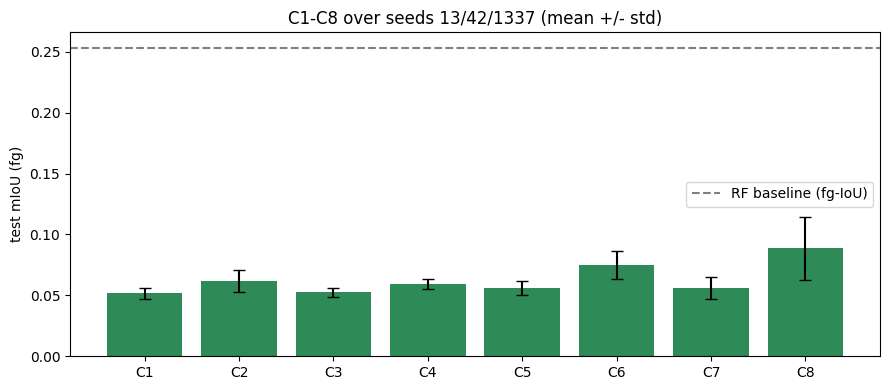

In [29]:

names = [c['name'] for c in GRID]
means = [RESULTS[n]['miou_mean'] for n in names]
stds = [RESULTS[n]['miou_std'] for n in names]
plt.figure(figsize=(9, 4))
plt.bar(names, means, yerr=stds, capsize=4, color='seagreen')
plt.axhline(BASELINE_RESULTS['rf_fg_iou'], ls='--', c='gray', label='RF baseline (fg-IoU)')
plt.ylabel('test mIoU (fg)'); plt.title('C1-C8 over seeds 13/42/1337 (mean +/- std)')
plt.legend(); plt.tight_layout(); plt.show()

### D.6 Leakage quantification - naive tile split vs field split

In [30]:
C2 = GRID[1]
leak = run_config(C2, NAIVE_SPLIT, seeds=SEEDS, quiet=True)
honest = RESULTS['C2']
print('C2 mIoU - field split (honest): {:.4f} +/- {:.4f}'.format(honest['miou_mean'], honest['miou_std']))
print('C2 mIoU - naive tile split     : {:.4f} +/- {:.4f}'.format(leak['miou_mean'], leak['miou_std']))
print('Leakage inflation              : {:+.4f} mIoU'.format(leak['miou_mean'] - honest['miou_mean']))
LEAKAGE = dict(field=honest['miou_mean'], naive=leak['miou_mean'])

C2 mIoU - field split (honest): 0.0620 +/- 0.0092
C2 mIoU - naive tile split     : 0.1038 +/- 0.0089
Leakage inflation              : +0.0418 mIoU


## Part E - Evaluation, robustness, calibration

Best config: C8 {'name': 'C8', 'arch': 'deeplab', 'use_nir': True, 'use_ndvi': False, 'loss': 'wce'}


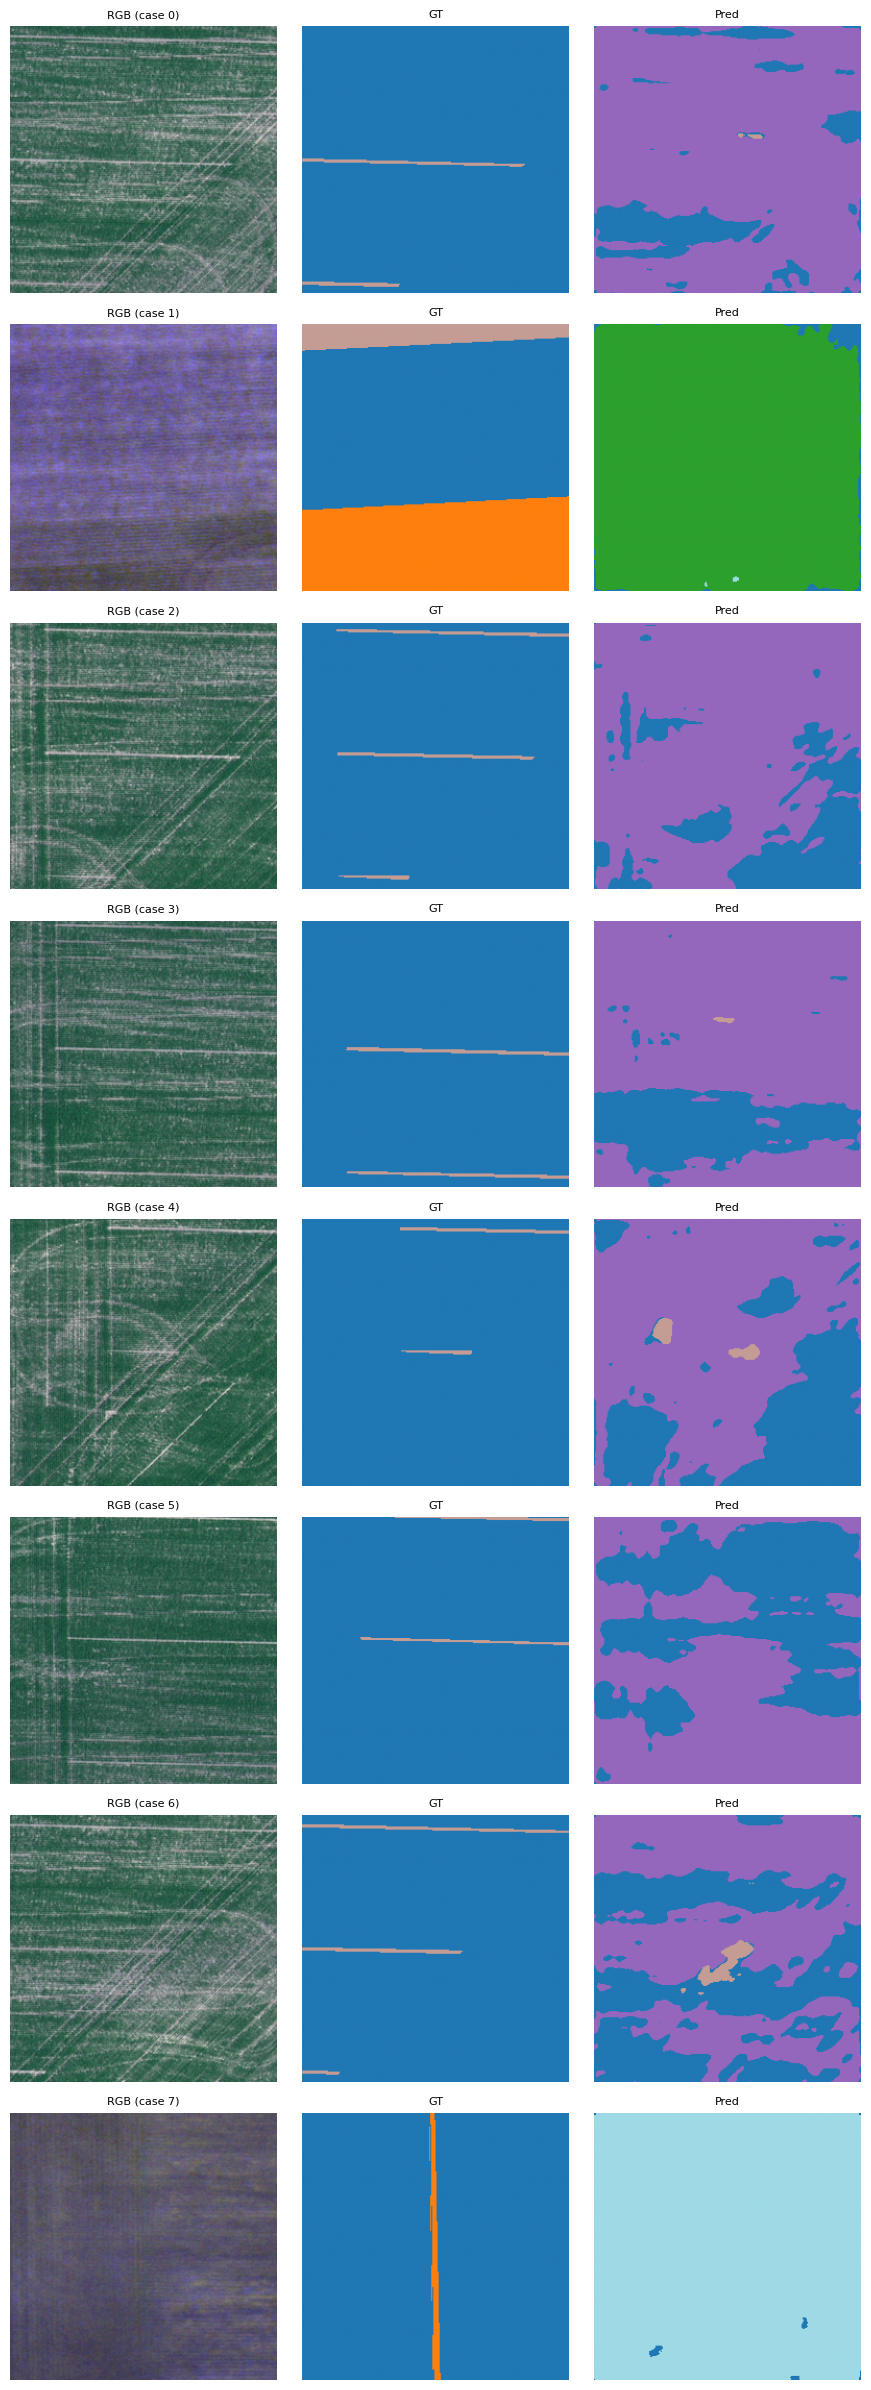

In [31]:
# E.1 Find the best config
best_name = max(RESULTS, key=lambda n: RESULTS[n]['miou_mean'])
best_cfg = RESULTS[best_name]['cfg']
print('Best config:', best_name, best_cfg)
ltr, lva, lte = make_loaders(None, best_cfg['use_ndvi'], best_cfg['use_nir'], 42, split_dict=FIELD_SPLIT)
BEST_MODEL = build_model(best_cfg, 42)
BEST_MODEL, _ = train_one(BEST_MODEL, ltr, lva, loss_name=best_cfg['loss'], seed=42, quiet=True)

@torch.no_grad()
def collect_failures(model, loader, k=8):
    model.eval()
    cases = []
    for x, y, multi, v in loader:
        xg = x.to(DEVICE)
        pred = model(xg).argmax(1).cpu()
        for b in range(x.shape[0]):
            yb, pb, vb = y[b], pred[b], v[b].bool()
            valid = vb & (yb != IGNORE_INDEX)
            if valid.sum() == 0: continue
            wrong = ((pb != yb) & valid).float().mean().item()
            rare = 0.0
            for ci in PRIORITY_ORDER[:2]:
                gt = (yb == ci+1) & valid
                if gt.sum() > 0: rare += ((pb[gt] != ci+1).float().mean().item())
            fp_healthy = (((pb != 0) & (yb == 0)) & valid).float().mean().item()
            cases.append((wrong + rare + fp_healthy, x[b].clone(), yb.clone(), pb.clone(), vb.clone()))
    cases.sort(key=lambda t: -t[0])
    return cases[:k]

FAILURES = collect_failures(BEST_MODEL, lte, k=8)
def to_rgb(x):
    img = x[:3].numpy().transpose(1, 2, 0)
    img = img * NORM_STD[:3] + NORM_MEAN[:3]
    return np.clip(img, 0, 1)

fig, axes = plt.subplots(len(FAILURES), 3, figsize=(9, 3*len(FAILURES)))
for i, (sc, x, yb, pb, vb) in enumerate(FAILURES):
    axes[i, 0].imshow(to_rgb(x)); axes[i, 0].set_title('RGB (case %d)' % i, fontsize=8)
    axes[i, 1].imshow(yb, vmin=0, vmax=NUM_CLASSES-1, cmap='tab20'); axes[i, 1].set_title('GT', fontsize=8)
    axes[i, 2].imshow(pb, vmin=0, vmax=NUM_CLASSES-1, cmap='tab20'); axes[i, 2].set_title('Pred', fontsize=8)
    for a in axes[i]: a.axis('off')
plt.tight_layout(); plt.show()

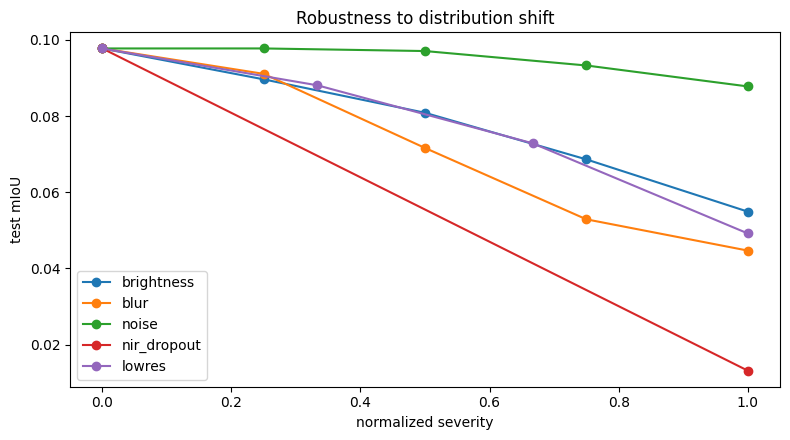

In [33]:
# E.2 Distribution-shift robustness
def perturb(x, kind, sev):
    x = x.clone()
    if kind == 'brightness': x[:3] = x[:3] + sev
    elif kind == 'noise': x = x + torch.randn_like(x) * sev
    elif kind == 'blur':
        ks = int(sev)
        if ks >= 1:
            k = 2*ks + 1
            w = torch.ones(x.shape[0], 1, k, k) / (k*k)
            x = F.conv2d(x[None], w, padding=ks, groups=x.shape[0])[0]
    elif kind == 'nir_dropout':
        if sev > 0.5: x[3] = float(NORM_MEAN[3])
    elif kind == 'lowres':
        f = max(1, int(sev))
        h, w = x.shape[-2:]
        small = F.interpolate(x[None], scale_factor=1.0/f, mode='bilinear', align_corners=False)
        x = F.interpolate(small, size=(h, w), mode='bilinear', align_corners=False)[0]
    return x

@torch.no_grad()
def eval_perturbed(model, loader, kind, sev):
    model.eval(); cm = torch.zeros(NUM_CLASSES, NUM_CLASSES)
    for x, y, _m, _v in loader:
        xp = torch.stack([perturb(x[b], kind, sev) for b in range(x.shape[0])]).to(DEVICE)
        pred = model(xp).argmax(1).cpu()
        cm += confusion_matrix(pred, y, NUM_CLASSES)
    return mean_iou(cm)

SHIFTS = {
    'brightness': [0.0, 0.1, 0.2, 0.3, 0.4],
    'blur': [0, 1, 2, 3, 4],
    'noise': [0.0, 0.05, 0.1, 0.2, 0.3],
    'nir_dropout': [0.0, 1.0],
    'lowres': [1, 2, 4, 8],
}
curves = {}
for kind, sevs in SHIFTS.items():
    curves[kind] = [eval_perturbed(BEST_MODEL, lte, kind, s) for s in sevs]

plt.figure(figsize=(8, 4.5))
for kind, sevs in SHIFTS.items():
    xs = np.linspace(0, 1, len(sevs))
    plt.plot(xs, curves[kind], marker='o', label=kind)
plt.xlabel('normalized severity'); plt.ylabel('test mIoU'); plt.title('Robustness to distribution shift')
plt.legend(); plt.tight_layout(); plt.show()

Expected Calibration Error (ECE): 0.1605


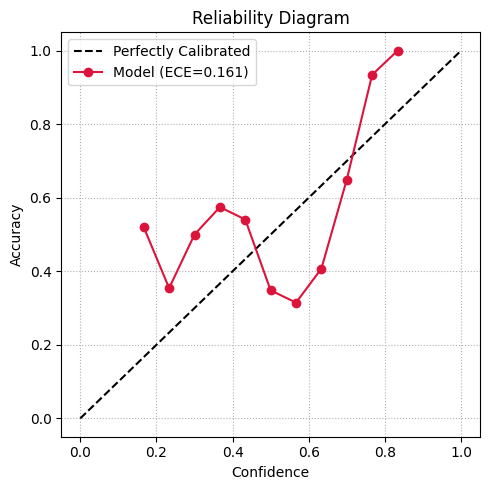

Cost-optimal Threshold: 0.65
Abstention Rule: Defer 36.4% of pixels to human review.
Accuracy on ALL pixels: 0.567
Accuracy on CONFIDENT pixels (Abstention applied): 0.410


In [38]:
# E.3 Calibration ECE and Business cost model
@torch.no_grad()
def gather_confidences(model, loader, max_px=400000):
    model.eval(); confs, corrects = [], []
    for x, y, _m, _v in loader:
        logits = model(x.to(DEVICE))
        p = F.softmax(logits, 1).cpu()
        conf, pred = p.max(1)
        valid = (y != IGNORE_INDEX)
        confs.append(conf[valid].reshape(-1)); corrects.append((pred[valid] == y[valid]).float().reshape(-1))
        if sum(c.numel() for c in confs) > max_px: break
    return torch.cat(confs).numpy(), torch.cat(corrects).numpy()

conf, corr = gather_confidences(BEST_MODEL, lte)

def expected_calibration_error(conf, corr, n_bins=15):
    bins = np.linspace(0, 1, n_bins+1)
    ece = 0.0; xs, accs, cfs = [], [], []
    for i in range(n_bins):
        m = (conf > bins[i]) & (conf <= bins[i+1])
        if m.sum() == 0: continue
        acc = corr[m].mean(); cf = conf[m].mean(); w = m.mean()
        ece += w * abs(acc - cf)
        xs.append((bins[i]+bins[i+1])/2); accs.append(acc); cfs.append(cf)
    return ece, np.array(xs), np.array(accs), np.array(cfs)

ece, xs, accs, cfs = expected_calibration_error(conf, corr)
print('Expected Calibration Error (ECE): {:.4f}'.format(ece))

# ================= MISSING PLOT ADDED =================
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], 'k--', label='Perfectly Calibrated')
plt.plot(xs, accs, marker='o', color='crimson', label='Model (ECE=%.3f)' % ece)
plt.xlabel('Confidence'); plt.ylabel('Accuracy'); plt.title('Reliability Diagram')
plt.legend(); plt.grid(True, ls=':'); plt.tight_layout(); plt.show()
# ======================================================

COST_FP = 5.0
COST_FN = 20.0
@torch.no_grad()
def foreground_scores(model, loader):
    model.eval(); S, T = [], []
    for x, y, multi, v in loader:
        p = F.softmax(model(x.to(DEVICE)), 1).cpu()
        fg_prob = 1 - p[:, 0]
        valid = (y != IGNORE_INDEX)
        fg_true = (y > 0).long()
        S.append(fg_prob[valid].reshape(-1)); T.append(fg_true[valid].reshape(-1))
    return torch.cat(S).numpy(), torch.cat(T).numpy()

sfg, tfg = foreground_scores(BEST_MODEL, lte)
thr_grid = np.linspace(0.05, 0.95, 19)
costs = [int((((sfg >= th).astype(int) == 1) & (tfg == 0)).sum()) * COST_FP +
         int((((sfg >= th).astype(int) == 0) & (tfg == 1)).sum()) * COST_FN for th in thr_grid]
best_th = thr_grid[np.argmin(costs)]

# ================= MISSING ABSTENTION COMPARISON ADDED =================
ABSTAIN_LO, ABSTAIN_HI = 0.35, 0.65
abstain_mask = (sfg > ABSTAIN_LO) & (sfg < ABSTAIN_HI)
confident_mask = ~abstain_mask
abstain_frac = float(abstain_mask.mean())

acc_all = float(((sfg >= best_th).astype(int) == tfg).mean())
acc_conf = float(((sfg[confident_mask] >= best_th).astype(int) == tfg[confident_mask]).mean())

print(f"Cost-optimal Threshold: {best_th:.2f}")
print(f"Abstention Rule: Defer {abstain_frac:.1%} of pixels to human review.")
print(f"Accuracy on ALL pixels: {acc_all:.3f}")
print(f"Accuracy on CONFIDENT pixels (Abstention applied): {acc_conf:.3f}")
# =======================================================================
CALIB = dict(ece=ece, best_th=float(best_th), abstain_frac=abstain_frac)

In [39]:
# E.4 Save
report_blob = {
    'classes': IDX2NAME,
    'class_frequency': freq.tolist(),
    'imbalance_ratio': float(imbalance),
    'split_sizes_field': {k: len(v) for k, v in FIELD_SPLIT.items()},
    'baselines': BASELINE_RESULTS,
    'grid': {n: {'cfg': RESULTS[n]['cfg'], 'miou_mean': RESULTS[n]['miou_mean'], 'miou_std': RESULTS[n]['miou_std']} for n in RESULTS},
    'leakage': LEAKAGE,
    'best_config': best_name,
    'calibration': CALIB,
    'cost_model': {'COST_FP': COST_FP, 'COST_FN': COST_FN},
}
with open('results_summary.json', 'w') as f:
    json.dump(report_blob, f, indent=2)
print('Results saved to results_summary.json. Use this to write your Lab2 Report.')

Results saved to results_summary.json. Use this to write your Lab2 Report.
